# Precios al consumidor en Chile, 2026: exploración, estacionalidad y agrupación de productos

Este cuaderno analiza el **detalle semanal de precios al consumidor** que publica ODEPA (Oficina de Estudios y Políticas Agrarias, Ministerio de Agricultura) en el portal de datos abiertos del Gobierno de Chile (datos.gob.cl). El archivo cubre desde la semana 1 (29-dic-2025) hasta la semana 47 (20-nov-2026).

Preguntas que quiero responder:
1. ¿Qué tan limpios y completos están los datos?
2. ¿Qué relación hay entre el precio mínimo, máximo y promedio, y qué variables explican sus cambios?
3. ¿Se notan efectos del calendario (Semana Santa, Fiestas Patrias, vacaciones)?
4. ¿Los productos se pueden agrupar según cómo se mueve su precio durante el año?

## 1. Librerías y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, silhouette_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
RUTA = "../data/precio_consumidor_2026.csv"
FIG = "../reports/"
PRECIOS = ["Precio minimo", "Precio maximo", "Precio promedio"]

df = pd.read_csv(RUTA, encoding="utf-8-sig", dtype=str)
for c in PRECIOS:
    df[c] = pd.to_numeric(df[c].str.replace(",", "."))   # el archivo usa coma decimal
df["Semana"] = df["Semana"].astype(int)
df["Mes"] = df["Mes"].astype(int)
df["ID region"] = df["ID region"].astype(int)
df = df.rename(columns={"Tipo de punto monitoreo": "Tipo_punto"})
print(df.shape)
df.head(3)

(292566, 15)


,Anio,Mes,Semana,Fecha inicio,Fecha termino,ID region,Region,Sector,Tipo_punto,Grupo,Producto,Unidad,Precio minimo,Precio maximo,Precio promedio
0,2026,1,1,2025-12-29,2026-01-02,4,Región de Coquimbo,La Serena,Carnicería,Carne bovina,Abastero,$/kilo,11890,11890,11890.0
1,2026,1,1,2025-12-29,2026-01-02,4,Región de Coquimbo,La Serena,Carnicería,Carne bovina,Asado Carnicero,$/kilo,11890,11890,11890.0
2,2026,1,1,2025-12-29,2026-01-02,4,Región de Coquimbo,La Serena,Carnicería,Carne bovina,Asado de tira,$/kilo,12490,12490,12490.0


## 2. Estructura y calidad de los datos

In [2]:
print(df.dtypes.to_string())
print("\nNulos por columna:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Precio minimo > maximo:", int((df['Precio minimo'] > df['Precio maximo']).sum()))
fuera = (df['Precio promedio'] < df['Precio minimo'] - .01) | (df['Precio promedio'] > df['Precio maximo'] + .01)
print("Promedio fuera del rango min-max:", int(fuera.sum()))
print("Precios <= 0:", int((df['Precio promedio'] <= 0).sum()))
print("Semanas:", df.Semana.min(), "a", df.Semana.max(), "| distintas:", df.Semana.nunique())
print("Regiones:", df.Region.nunique(), "| sectores:", df.Sector.nunique(),
      "| grupos:", df.Grupo.nunique(), "| productos:", df.Producto.nunique())

Anio                   str
Mes                  int64
Semana               int64
Fecha inicio           str
Fecha termino          str
ID region            int64
Region                 str
Sector                 str
Tipo_punto             str
Grupo                  str
Producto               str
Unidad                 str
Precio minimo        int64
Precio maximo        int64
Precio promedio    float64

Nulos por columna: 0


Filas duplicadas: 0
Precio minimo > maximo: 0
Promedio fuera del rango min-max: 0
Precios <= 0: 0
Semanas: 1 a 47 | distintas: 47
Regiones: 9 | sectores: 41 | grupos: 7 | productos: 271


Los datos vienen limpios: sin nulos, sin duplicados y con precios coherentes (el mínimo nunca supera al máximo y el promedio siempre queda entre ambos). Un detalle práctico: hay 19 unidades de medida distintas (kilo, unidad, bandeja, caja, litro, etc.), así que **no se pueden comparar precios entre productos sin separar por unidad**.

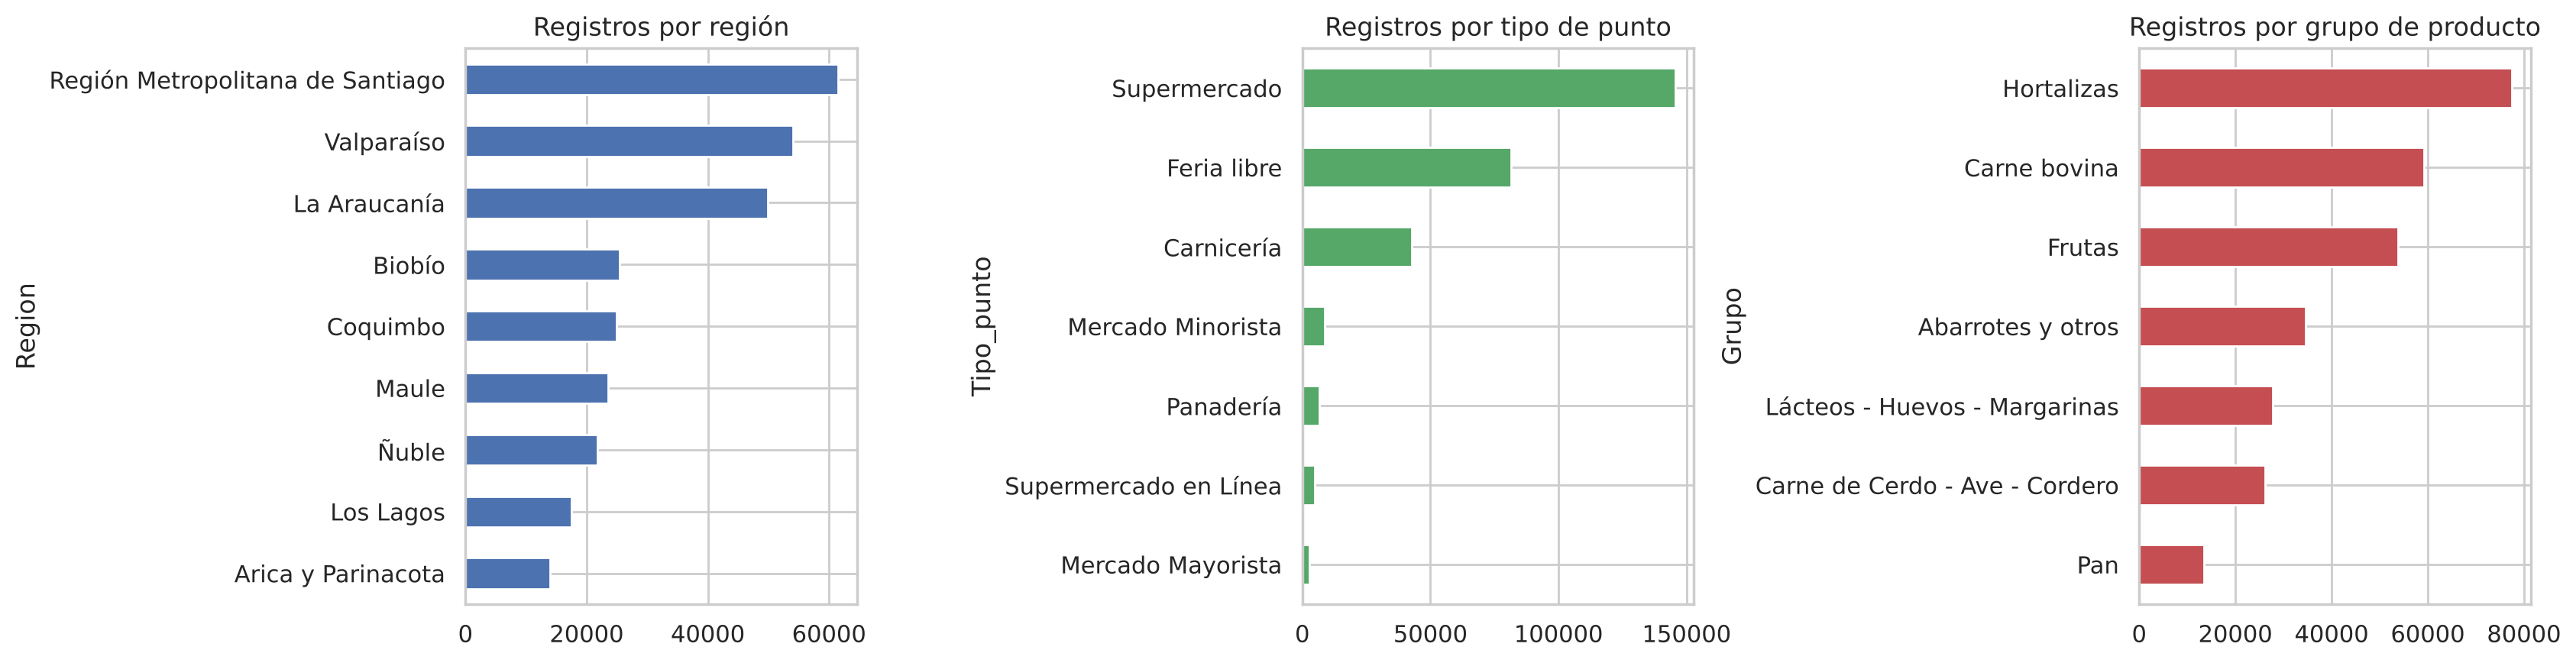

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
df.Region.str.replace("Región de ", "").str.replace("Región del ", "").value_counts().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Registros por región")
df.Tipo_punto.value_counts().plot.barh(ax=ax[1], color="#55A868"); ax[1].set_title("Registros por tipo de punto")
df.Grupo.value_counts().plot.barh(ax=ax[2], color="#C44E52"); ax[2].set_title("Registros por grupo de producto")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG + "01_distribucion_registros.png", dpi=130); plt.show()

Tres regiones (Metropolitana, Valparaíso y La Araucanía) concentran más de la mitad de los registros, y la mitad de las mediciones viene de supermercados. Conviene tenerlo presente: las conclusiones pesan más en esas zonas y canales.

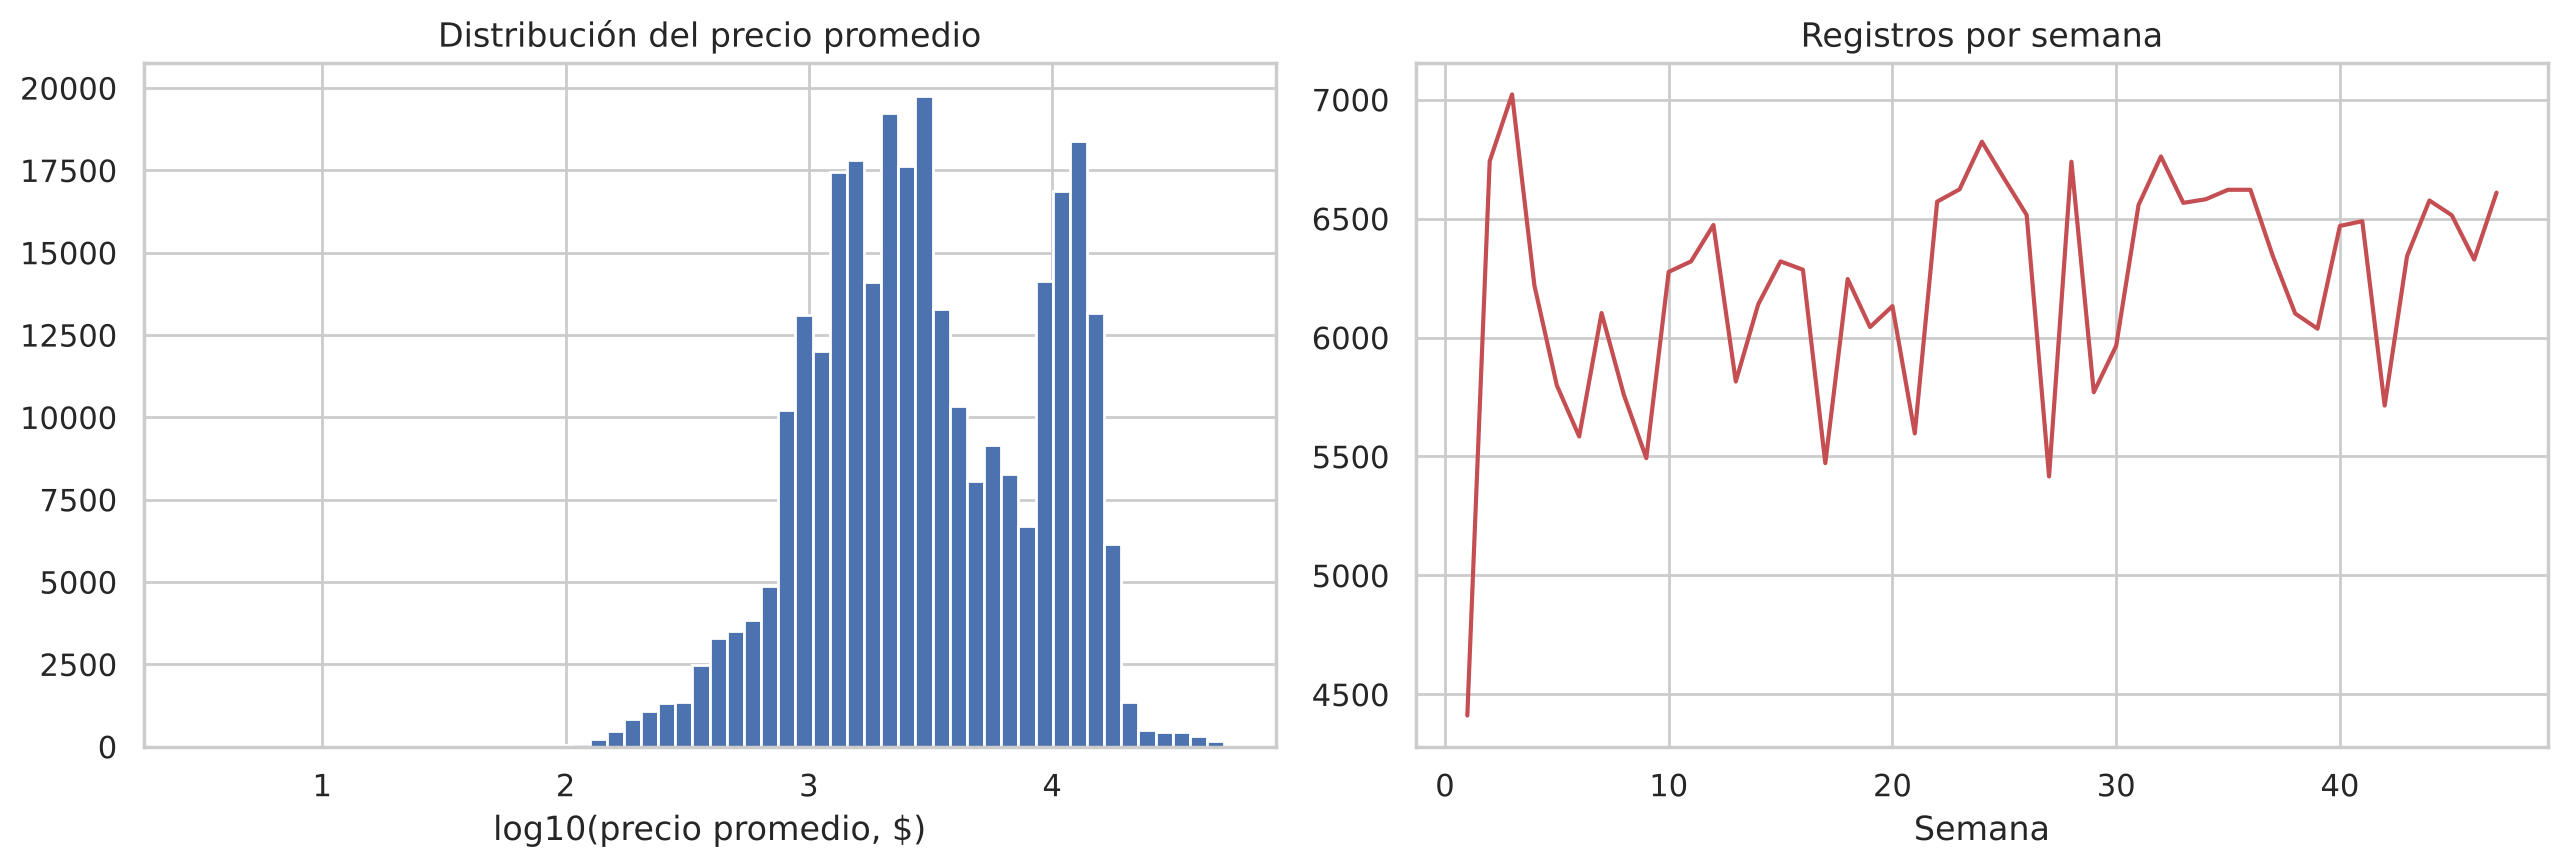

,Precio minimo,Precio maximo,Precio promedio
count,292566.0,292566.0,292566.0
mean,4696.0,5584.0,5129.0
std,4966.0,5768.0,5307.0
min,3.0,3.0,3.0
25%,1290.0,1500.0,1400.0
50%,2500.0,2990.0,2757.0
75%,7590.0,8990.0,8290.0
max,51000.0,57909.0,51000.0


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(np.log10(df["Precio promedio"]), bins=60, color="#4C72B0")
ax[0].set_xlabel("log10(precio promedio, $)"); ax[0].set_title("Distribución del precio promedio")
df.groupby("Semana").size().plot(ax=ax[1], color="#C44E52"); ax[1].set_title("Registros por semana"); ax[1].set_xlabel("Semana")
plt.tight_layout(); plt.savefig(FIG + "02_distribucion_precios.png", dpi=130); plt.show()
df[PRECIOS].describe().round(0)

## 3. Relación entre precio mínimo, máximo y promedio

Primero preparo una variable clave: la **variación semanal** de cada serie (misma región, sector, tipo de punto, producto y unidad), medida como cambio logarítmico respecto de la semana anterior. Solo se calcula cuando existen semanas consecutivas.

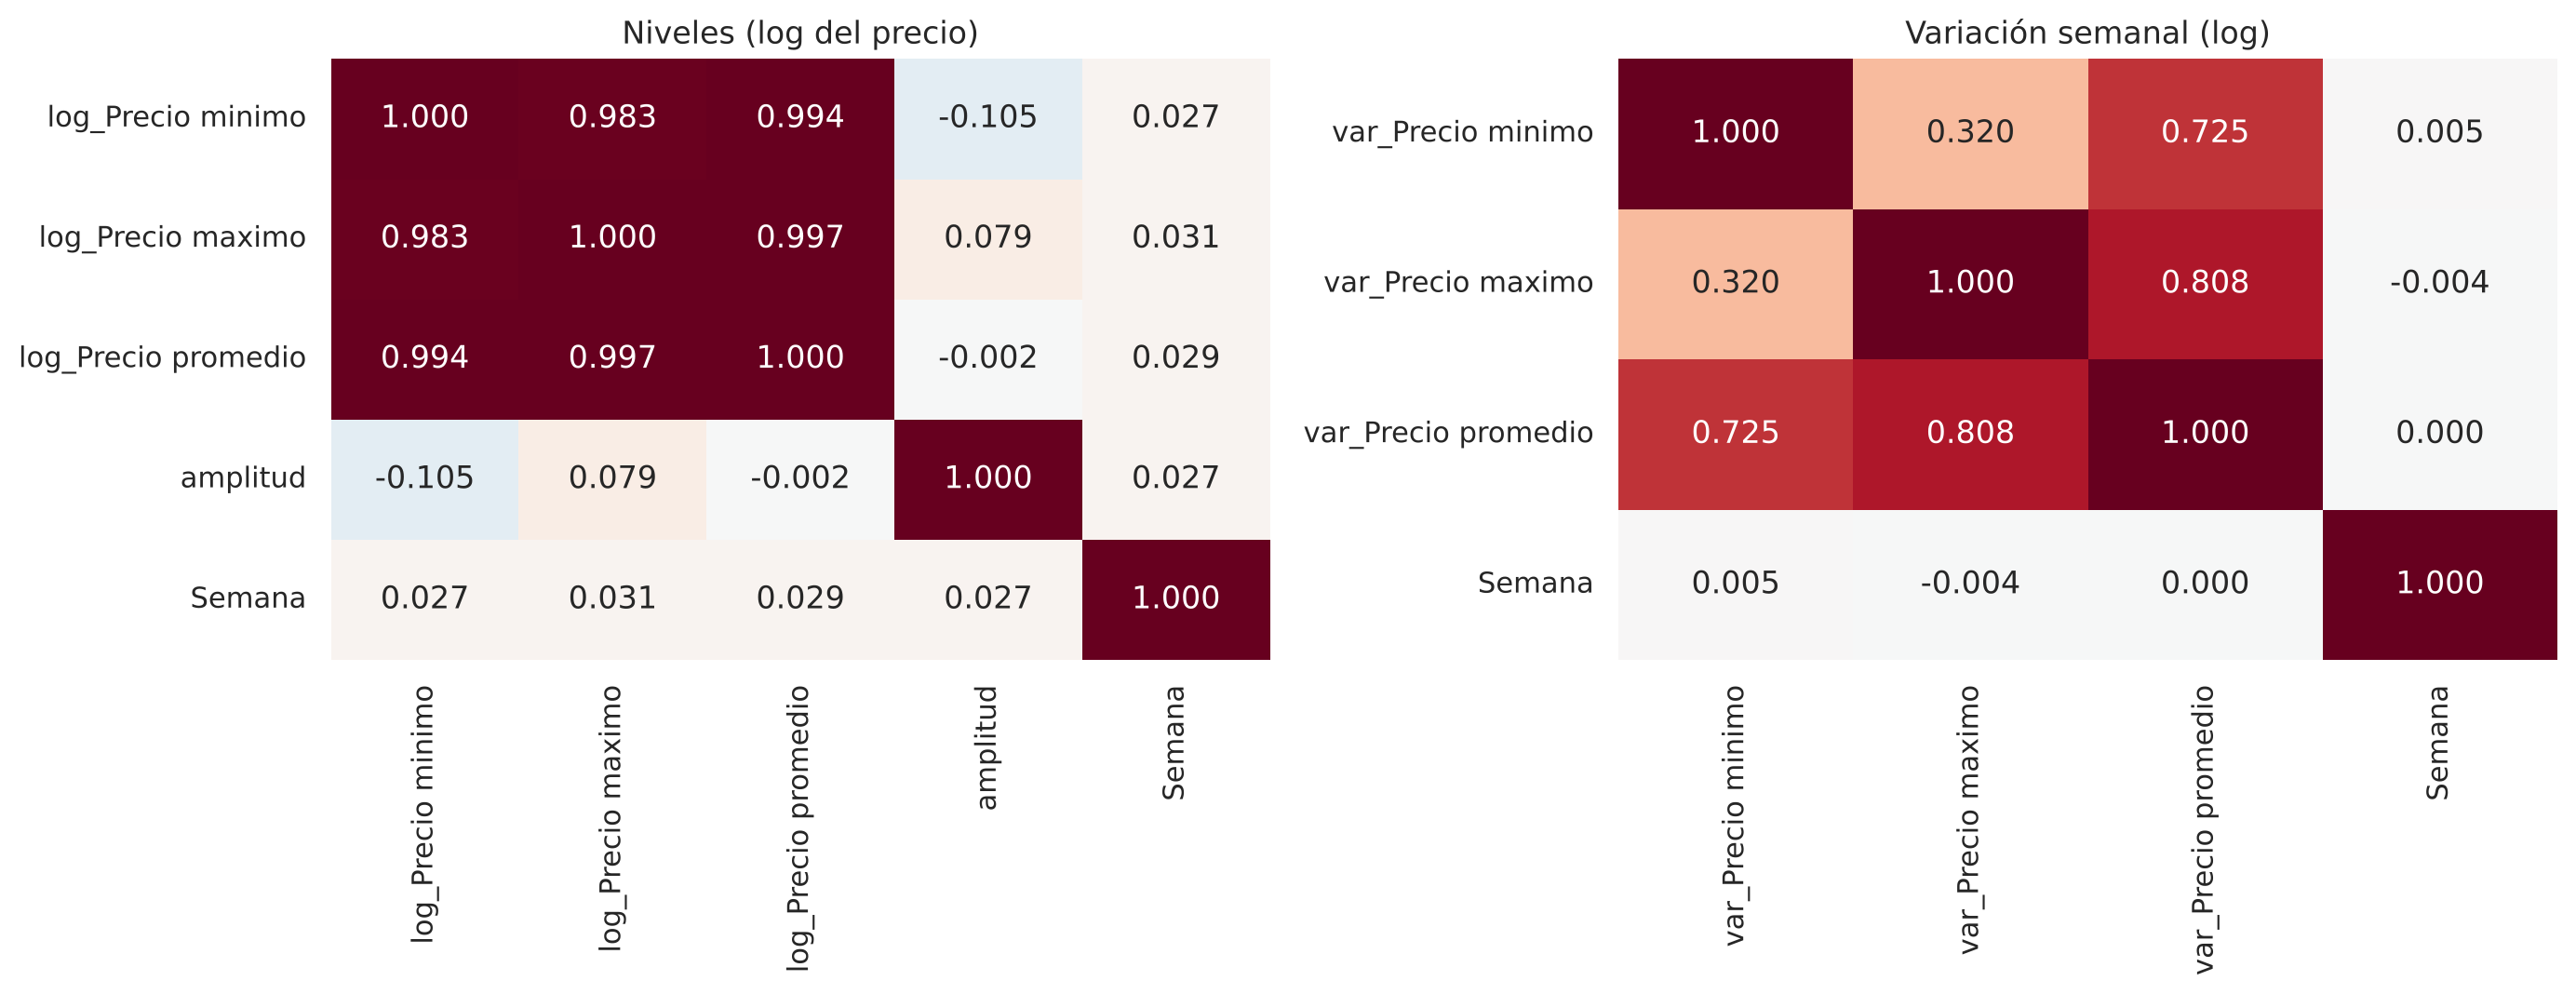

In [5]:
clave = ["Region", "Sector", "Tipo_punto", "Producto", "Unidad"]
df = df.sort_values(clave + ["Semana"]).reset_index(drop=True)
g = df.groupby(clave)
for c in PRECIOS:
    df["log_" + c] = np.log(df[c])
    df["var_" + c] = np.log(df[c] / g[c].shift(1)).where(g["Semana"].diff() == 1)
df["amplitud"] = (df["Precio maximo"] - df["Precio minimo"]) / df["Precio promedio"]

niveles = df[["log_" + c for c in PRECIOS] + ["amplitud", "Semana"]].corr()
variac = df[["var_" + c for c in PRECIOS] + ["Semana"]].corr()
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(niveles.round(3), annot=True, fmt=".3f", cmap="RdBu_r", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Niveles (log del precio)")
sns.heatmap(variac.round(3), annot=True, fmt=".3f", cmap="RdBu_r", center=0, ax=ax[1], cbar=False)
ax[1].set_title("Variación semanal (log)")
plt.tight_layout(); plt.savefig(FIG + "03_matriz_correlacion.png", dpi=130); plt.show()

En niveles, el mínimo, el máximo y el promedio son casi lo mismo (correlaciones entre 0,98 y 0,997): usar uno para predecir otro no aporta información. En variaciones se separan más: el mínimo y el máximo se correlacionan solo 0,32. La semana del año no se correlaciona con ninguno, es decir, no hay una tendencia general al alza o a la baja.

## 4. ¿Qué variables explican el precio? Importancia de variables (XGBoost)

{'Nivel minimo': 0.986, 'Nivel maximo': 0.989, 'Nivel promedio': 0.991, 'Variación minimo': -0.15, 'Variación maximo': -0.307, 'Variación promedio': -0.146}


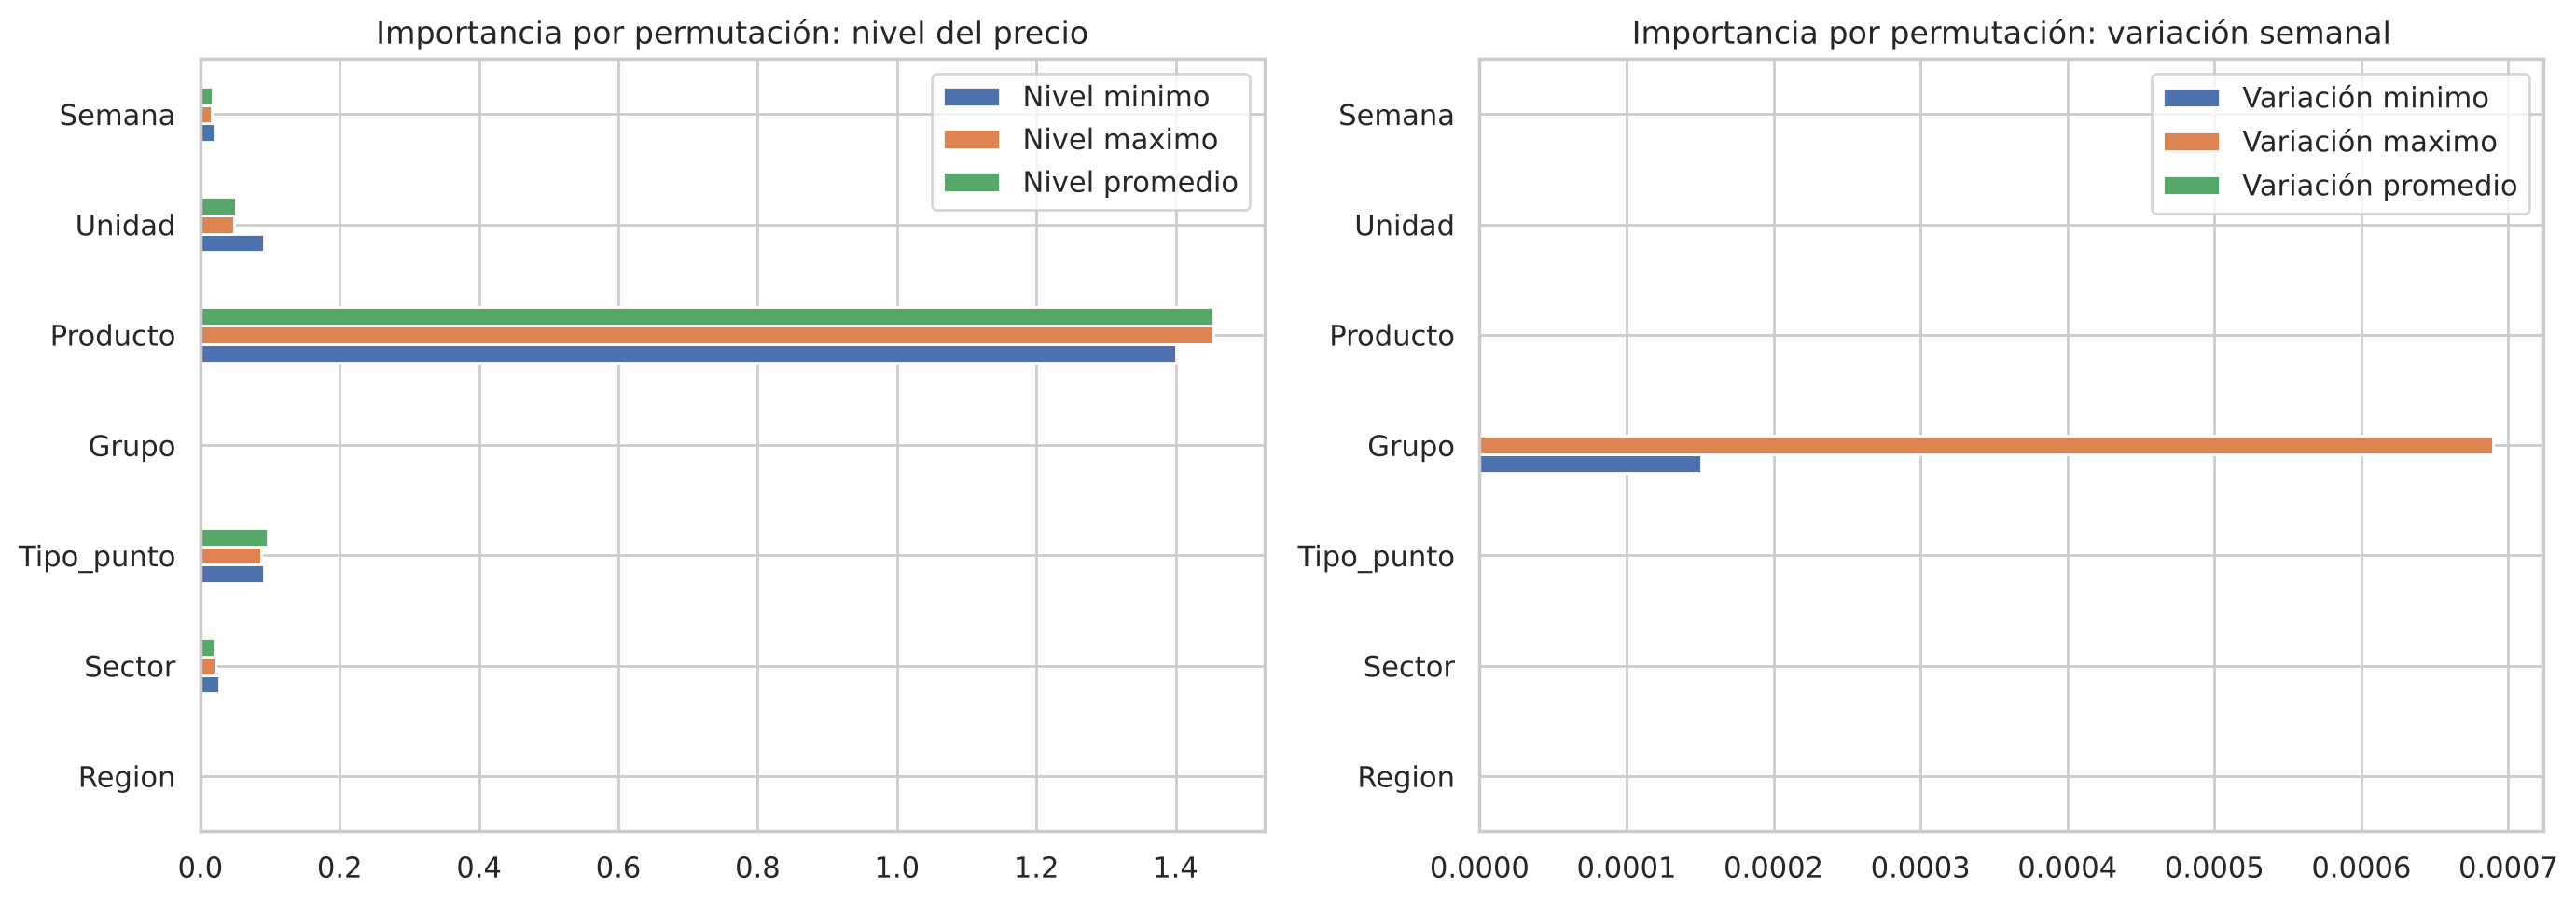

,Nivel minimo,Nivel maximo,Nivel promedio,Variación minimo,Variación maximo,Variación promedio
Region,0.0006,0.0004,0.0007,-0.0049,-0.0060,-0.0025
Sector,0.0268,0.0222,0.0201,-0.0347,-0.0559,-0.0243
Tipo_punto,0.0914,0.0874,0.0961,-0.0105,-0.0625,-0.0158
Grupo,0.0003,0.0003,0.0003,0.0002,0.0007,-0.0012
Producto,1.4012,1.4544,1.4545,-0.0215,-0.0660,-0.0158
Unidad,0.0919,0.0484,0.0512,-0.0001,-0.0000,-0.0001
Semana,0.0199,0.0165,0.0176,0.0000,0.0000,0.0000


In [6]:
cats = ["Region", "Sector", "Tipo_punto", "Grupo", "Producto", "Unidad"]
for c in cats:
    df[c] = df[c].astype("category")
feats = cats + ["Semana"]

def ajustar(objetivo, train, test):
    m = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist",
                     enable_categorical=True, n_jobs=-1, random_state=42)
    m.fit(train[feats], train[objetivo])
    r2 = r2_score(test[objetivo], m.predict(test[feats]))
    s = test.sample(min(20000, len(test)), random_state=1)
    pi = permutation_importance(m, s[feats], s[objetivo], n_repeats=3, random_state=1, n_jobs=1)
    return r2, pd.Series(pi.importances_mean, feats)

azar = np.random.RandomState(0).rand(len(df)) < 0.8
imp, r2s = {}, {}
for c in PRECIOS:                              # nivel: partición aleatoria 80/20
    r2s["Nivel " + c.split()[1]], imp["Nivel " + c.split()[1]] = ajustar("log_" + c, df[azar], df[~azar])
d = df.dropna(subset=["var_Precio promedio"])
tr, te = d[d.Semana <= 38], d[d.Semana > 38]    # variación: entrenar con semanas 1-38, probar en 39-47
for c in PRECIOS:
    r2s["Variación " + c.split()[1]], imp["Variación " + c.split()[1]] = ajustar("var_" + c, tr, te)
imp = pd.DataFrame(imp)
print({k: round(v, 3) for k, v in r2s.items()})
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp.filter(like="Nivel").clip(lower=0).plot.barh(ax=ax[0]); ax[0].set_title("Importancia por permutación: nivel del precio")
imp.filter(like="Variación").clip(lower=0).plot.barh(ax=ax[1]); ax[1].set_title("Importancia por permutación: variación semanal")
plt.tight_layout(); plt.savefig(FIG + "04_importancia_variables.png", dpi=130); plt.show()
imp.round(4)

**Lectura.** Para el *nivel* del precio el modelo acierta casi todo (R² entre 0,986 y 0,991) y la variable que manda es el producto, algo esperable. Para la *variación semanal* el R² sale negativo, es decir, peor que predecir el promedio: con las variables disponibles (región, producto, tipo de punto, semana) **no se puede explicar por qué un precio sube o baja de una semana a otra**. Para eso harían falta variables externas como clima, dólar o combustibles.

## 5. Efectos del calendario

Marco las semanas que contienen un evento relevante y comparo la variación semanal de cada grupo de productos en esas semanas contra el resto del año. Para no darle más peso a los productos con más registros, primero promedio por producto y semana.

In [7]:
df["ini"] = pd.to_datetime(df["Fecha inicio"]); df["fin"] = pd.to_datetime(df["Fecha termino"])
sem = df.groupby("Semana")[["ini", "fin"]].first()
eventos = {"Año Nuevo": ["2026-01-01"], "Semana Santa": ["2026-04-03", "2026-04-04"],
           "Día del Trabajo": ["2026-05-01"], "Glorias Navales": ["2026-05-21"],
           "Fiestas Patrias": ["2026-09-18", "2026-09-19"], "Todos los Santos": ["2026-11-01"]}
for k, fechas in eventos.items():
    sem[k] = [int(any(r.ini <= pd.Timestamp(f) <= r.fin + pd.Timedelta(days=2) for f in fechas)) for r in sem.itertuples()]
sem["Vacaciones invierno"] = [int(pd.Timestamp("2026-06-22") <= r.ini <= pd.Timestamp("2026-07-03")) for r in sem.itertuples()]
nombres = list(eventos) + ["Vacaciones invierno"]
print({k: list(sem.index[sem[k] == 1]) for k in nombres})

d = df.dropna(subset=["var_Precio promedio"])
ps = (d.groupby(["Grupo", "Producto", "Unidad", "Semana"], observed=True)["var_Precio promedio"].mean()
        .reset_index().merge(sem[nombres].reset_index(), on="Semana"))
filas = []
for k in nombres:
    for gr, x in ps.groupby("Grupo", observed=True):
        a, b = x[x[k] == 1]["var_Precio promedio"], x[x[k] == 0]["var_Precio promedio"]
        if len(a) > 30:
            filas.append((k, gr, a.mean() * 100, b.mean() * 100, stats.ttest_ind(a, b, equal_var=False)[1]))
efectos = pd.DataFrame(filas, columns=["evento", "grupo", "var_evento_%", "var_resto_%", "p"])
efectos["diferencia_pp"] = efectos["var_evento_%"] - efectos["var_resto_%"]
efectos.sort_values("p").round(3).head(10)

{'Año Nuevo': [1], 'Semana Santa': [14], 'Día del Trabajo': [18], 'Glorias Navales': [21], 'Fiestas Patrias': [38], 'Todos los Santos': [44], 'Vacaciones invierno': [26, 27]}


,evento,grupo,var_evento_%,var_resto_%,p,diferencia_pp
3,Semana Santa,Lácteos - Huevos - Margarinas,12.534,-0.399,0.000,12.934
24,Vacaciones invierno,Lácteos - Huevos - Margarinas,-2.384,-0.062,0.000,-2.321
0,Semana Santa,Abarrotes y otros,-3.966,0.151,0.000,-4.117
20,Vacaciones invierno,Abarrotes y otros,4.664,-0.148,0.001,4.812
19,Todos los Santos,Lácteos - Huevos - Margarinas,-1.022,-0.142,0.001,-0.879
17,Todos los Santos,Frutas,3.455,-0.291,0.002,3.746
10,Glorias Navales,Hortalizas,-0.908,0.470,0.015,-1.378
18,Todos los Santos,Hortalizas,-2.060,0.494,0.020,-2.554
21,Vacaciones invierno,Carne bovina,-0.221,0.210,0.036,-0.432
12,Fiestas Patrias,Abarrotes y otros,-1.093,0.087,0.039,-1.179


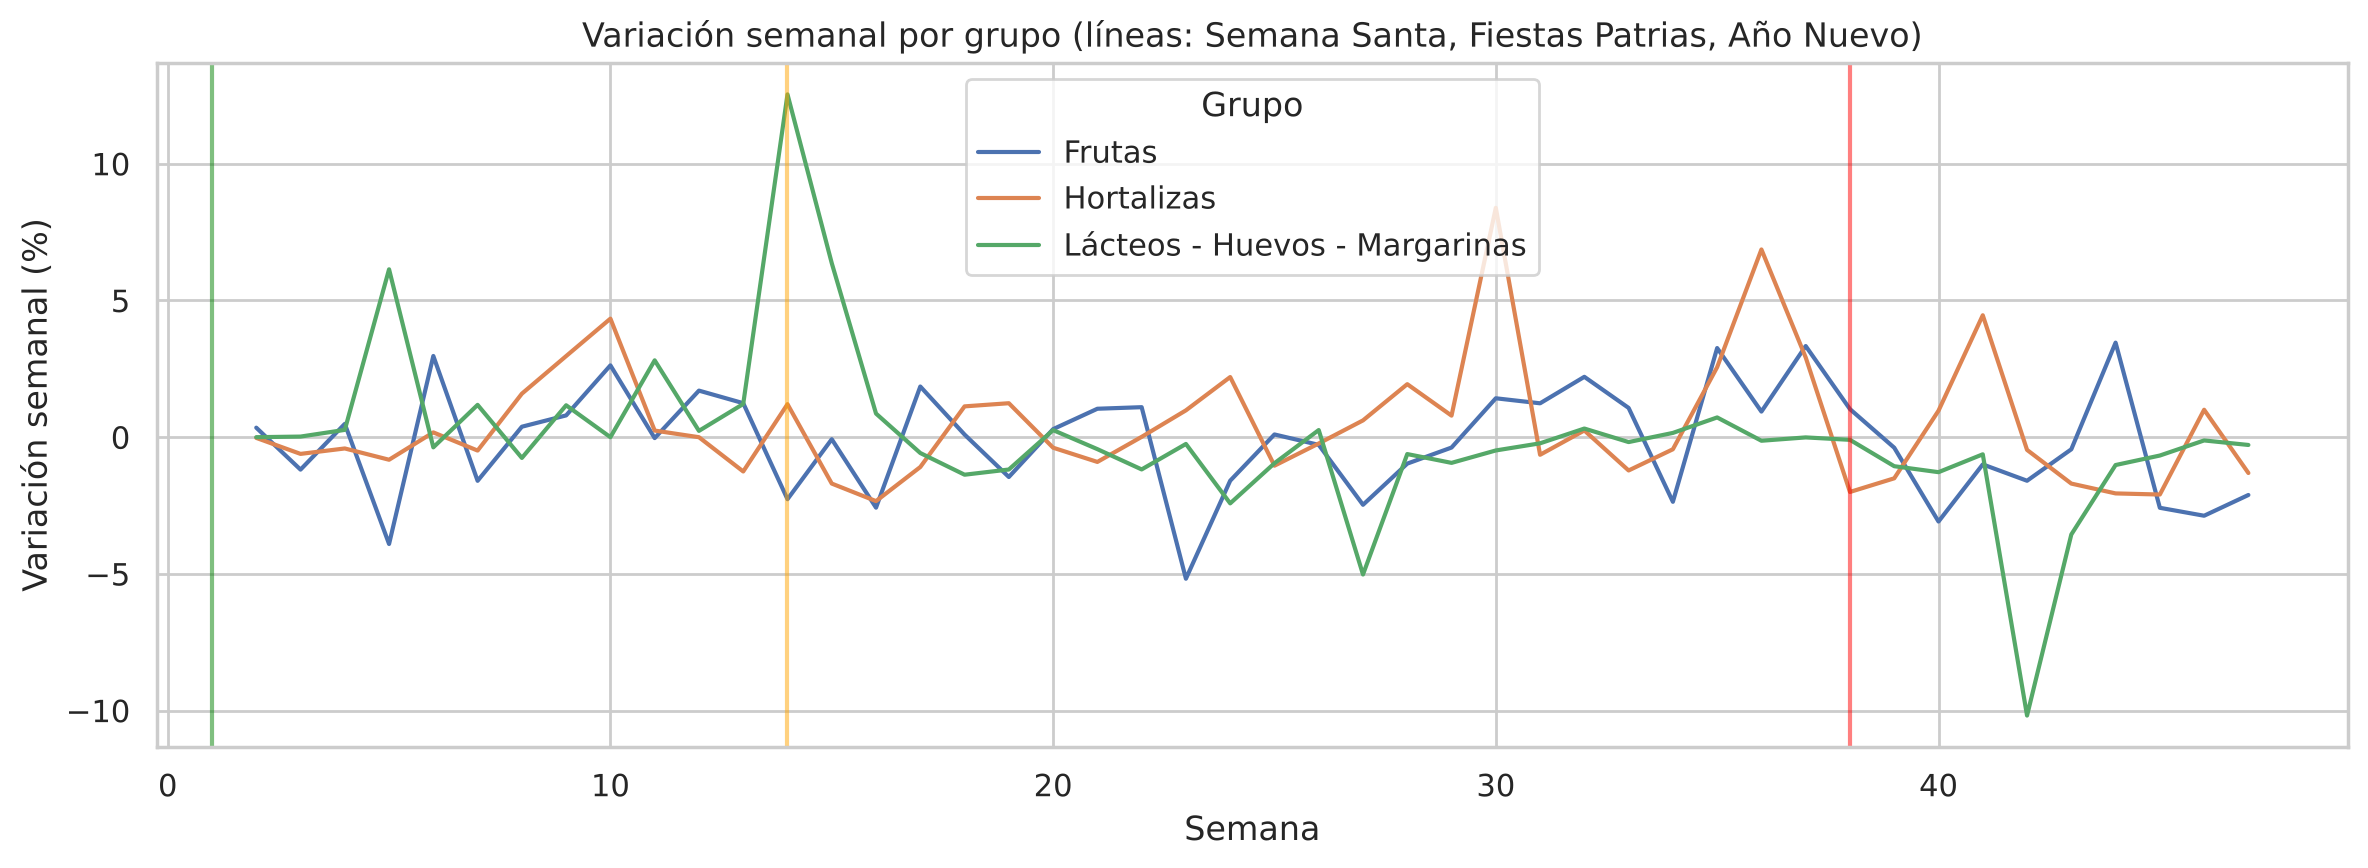

In [8]:
w = ps.groupby(["Grupo", "Semana"], observed=True)["var_Precio promedio"].mean().unstack(0) * 100
fig, ax = plt.subplots(figsize=(12, 4.5))
w[["Frutas", "Hortalizas", "Lácteos - Huevos - Margarinas"]].plot(ax=ax)
for k, col in [("Semana Santa", "orange"), ("Fiestas Patrias", "red"), ("Año Nuevo", "green")]:
    for s in sem.index[sem[k] == 1]:
        ax.axvline(s, c=col, alpha=.5)
ax.set_ylabel("Variación semanal (%)")
ax.set_title("Variación semanal por grupo (líneas: Semana Santa, Fiestas Patrias, Año Nuevo)")
plt.tight_layout(); plt.savefig(FIG + "05_variacion_semanal_eventos.png", dpi=130); plt.show()

In [9]:
huevos = df[df.Grupo.str.startswith("Lácteos") & df.Producto.str.startswith("Huevo")]
t = huevos.groupby(["Producto", "Semana"], observed=True)["Precio promedio"].median().unstack()
(t.loc[:, 12:16].pct_change(axis=1) * 100).round(1).dropna(how="all")

Semana,12,13,14,15,16
Producto,,,,,
Huevo blanco - Extra,NaN,315.0,-75.3,8.2,3.5
Huevo blanco - Jumbo,NaN,NaN,NaN,7.4,-55.6
Huevo blanco - Primera,NaN,358.1,-73.0,2.3,0.6
Huevo blanco - Segunda,NaN,34.8,-5.8,11.6,1.2
Huevo blanco - Super,NaN,107.1,-36.9,3.8,5.0
Huevo blanco - Tercera,NaN,NaN,NaN,5.4,0.2
Huevo blanco extra grande (extra),NaN,0.6,-0.8,0.2,0.7
Huevo blanco grande (primera),NaN,-0.1,-0.7,0.6,1.2
Huevo color - Extra,NaN,-4.5,25.0,6.7,2.5


El efecto más claro es **Semana Santa en lácteos y huevos**: ese grupo sube 12,5% en la semana 14 frente a -0,4% el resto del año, y se explica por el huevo de color (entre +25% y +75% según calidad). Los otros efectos son más pequeños y no los puedo distinguir de la estacionalidad natural, porque cada evento ocurre una sola vez en un solo año.

## 6. Estacionalidad mensual

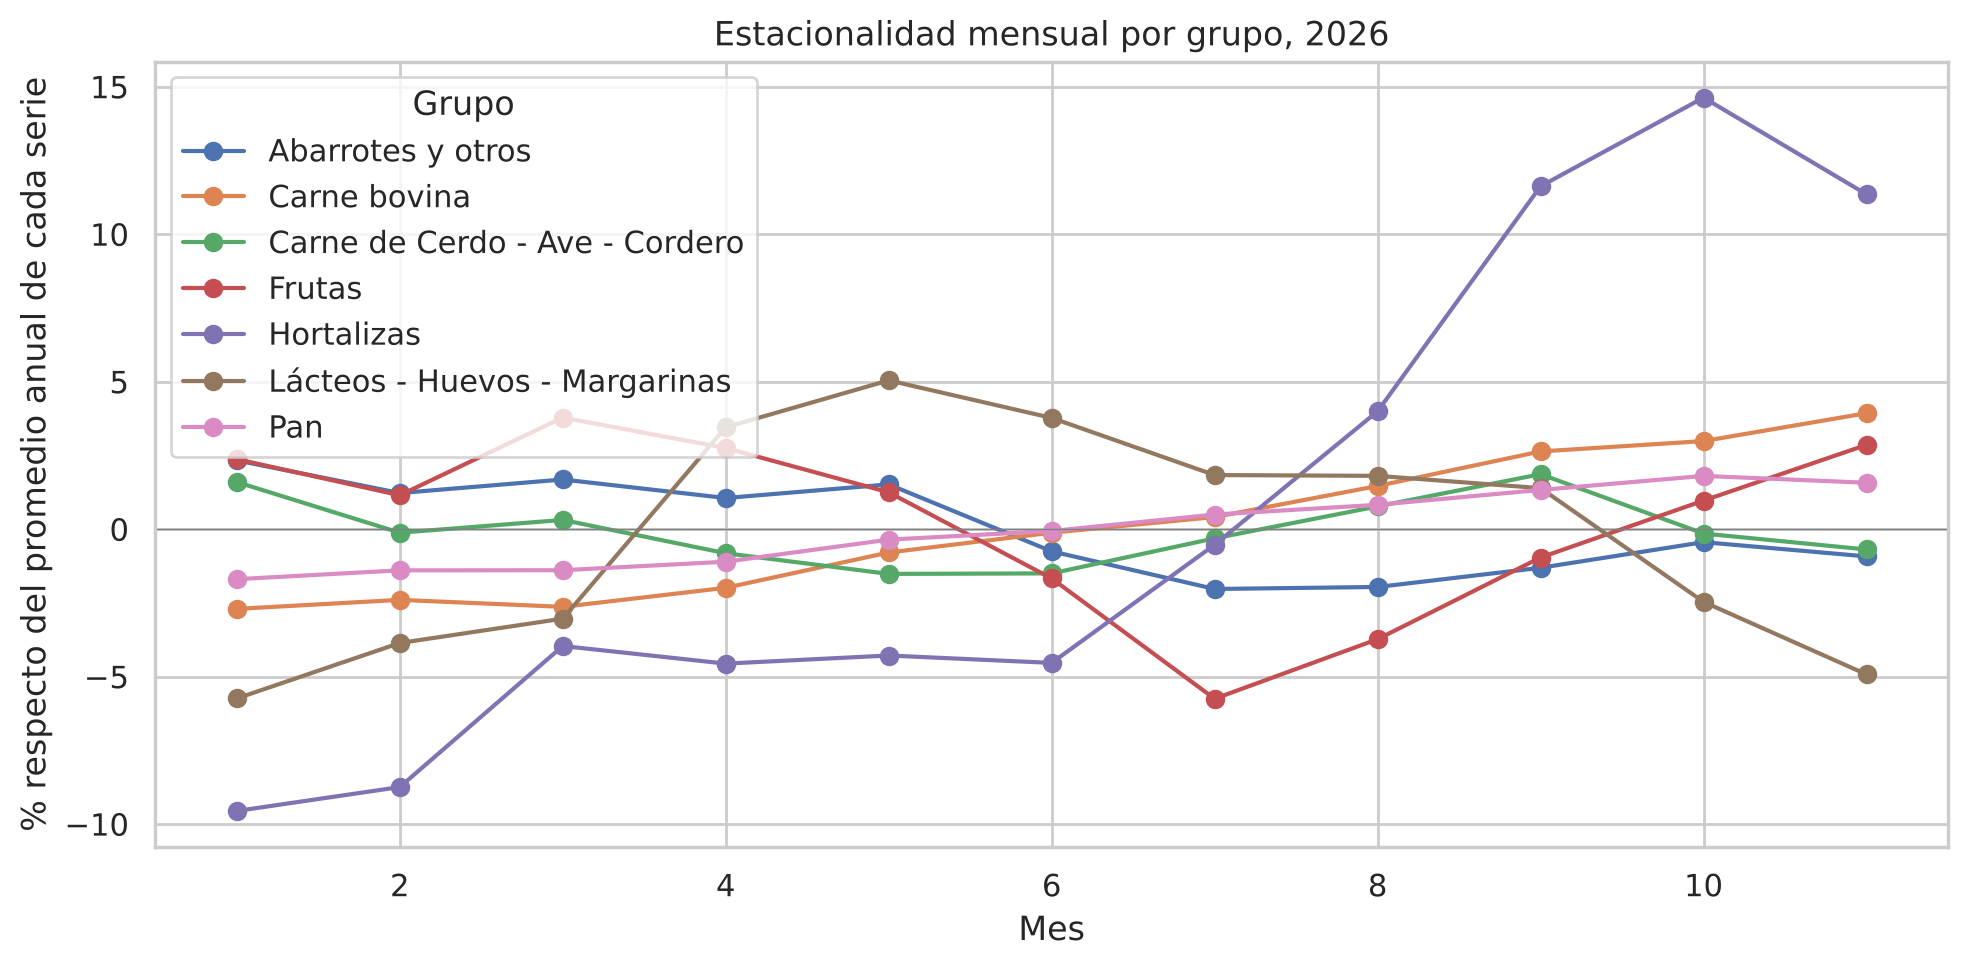

Grupo,Abarrotes y otros,Carne bovina,Carne de Cerdo - Ave - Cordero,Frutas,Hortalizas,Lácteos - Huevos - Margarinas,Pan
Mes,,,,,,,
1,2.3,-2.7,1.6,2.4,-9.6,-5.7,-1.7
2,1.2,-2.4,-0.1,1.1,-8.7,-3.9,-1.4
3,1.7,-2.6,0.3,3.8,-4.0,-3.0,-1.4
4,1.1,-2.0,-0.8,2.7,-4.6,3.5,-1.1
5,1.5,-0.8,-1.5,1.2,-4.3,5.0,-0.4
6,-0.8,-0.1,-1.5,-1.7,-4.5,3.8,-0.1
7,-2.0,0.4,-0.3,-5.8,-0.5,1.8,0.5
8,-2.0,1.5,0.8,-3.7,4.0,1.8,0.8
9,-1.3,2.6,1.9,-1.0,11.6,1.4,1.3


In [10]:
df["lp_centrado"] = df["log_Precio promedio"] - df.groupby(clave, observed=True)["log_Precio promedio"].transform("mean")
mensual = df.groupby(["Grupo", "Mes"], observed=True)["lp_centrado"].mean().unstack(0) * 100
fig, ax = plt.subplots(figsize=(10, 5))
mensual.plot(ax=ax, marker="o"); ax.axhline(0, c="gray", lw=.5)
ax.set_ylabel("% respecto del promedio anual de cada serie"); ax.set_title("Estacionalidad mensual por grupo, 2026")
plt.tight_layout(); plt.savefig(FIG + "06_estacionalidad_mensual.png", dpi=130); plt.show()
mensual.round(1)

Las hortalizas son las que más cambian: parten entre 9% y 10% bajo su promedio en enero-febrero y llegan a 15% sobre su promedio en octubre. Las frutas hacen casi lo opuesto, con el mínimo en julio. Pan, abarrotes y carnes se mueven poco.

## 7. Clustering: agrupar productos por la forma de su precio

La idea es juntar productos cuyo precio se mueve parecido a lo largo del año, sin importar cuánto cuestan. Pasos:
1. Calculo el precio mediano nacional de cada producto y unidad por semana.
2. Me quedo con las series que tienen al menos 40 de las 47 semanas (rellenando huecos por interpolación).
3. Trabajo con el logaritmo del precio, resto el promedio de cada serie y lo divido por su desviación. Así queda solo la **forma** de la curva.
4. Aplico K-means y elijo el número de grupos con el coeficiente de silueta.

In [11]:
serie = df.groupby(["Producto", "Unidad", "Semana"], observed=True)["Precio promedio"].median().unstack()
serie = serie[serie.notna().sum(axis=1) >= 40]
serie = serie.T.interpolate(limit_direction="both").T
L = np.log(serie)
X = L.sub(L.mean(axis=1), axis=0)
X = X.div(X.std(axis=1).replace(0, 1), axis=0)
print("Series usadas:", X.shape[0])
sil = {k: round(silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)), 3) for k in range(2, 8)}
print("Silueta por número de grupos:", sil)

Series usadas: 206
Silueta por número de grupos: {2: 0.23, 3: 0.263, 4: 0.24, 5: 0.239, 6: 0.201, 7: 0.23}


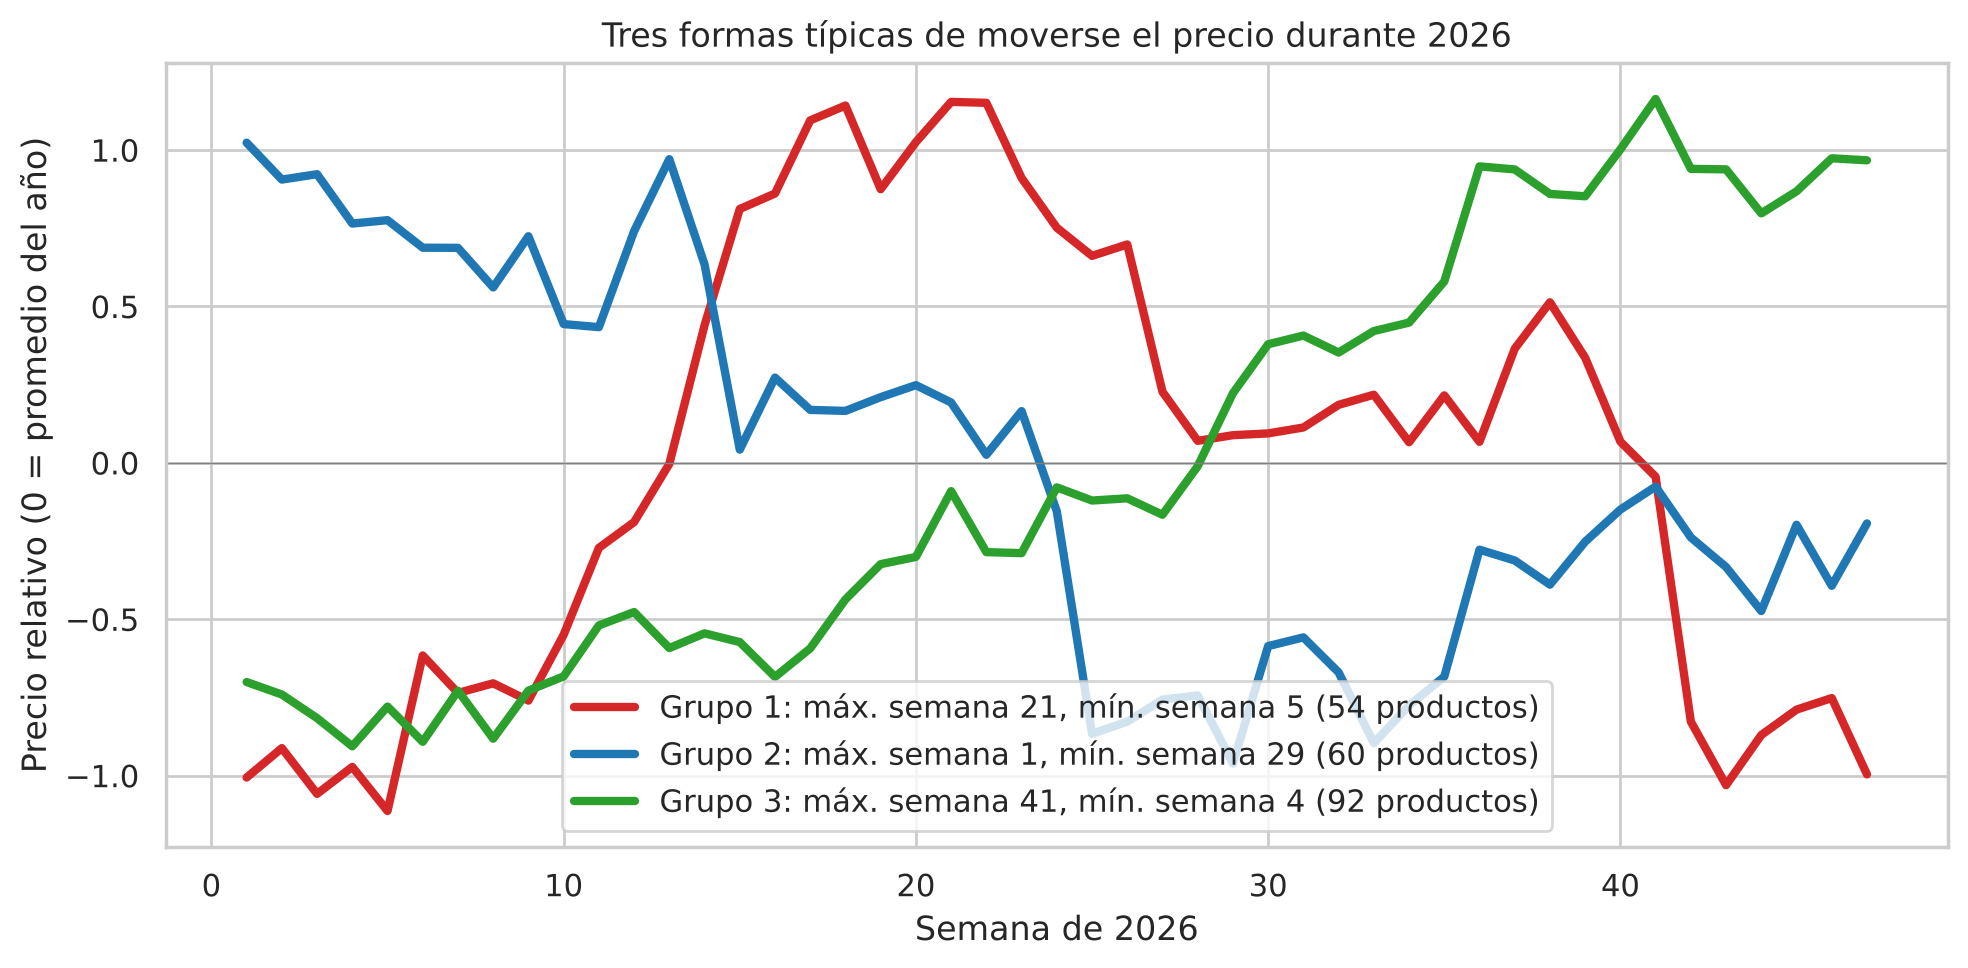

cluster                          1   2   3
grupo                                     
Abarrotes y otros                1  38   4
Carne bovina                     0   2  22
Carne de Cerdo - Ave - Cordero   3   6   5
Frutas                          14   9  10
Hortalizas                       1   4  39
Lácteos - Huevos - Margarinas   35   1   7
Pan                              0   0   5


,productos,rango_mediano_pct
cluster,,
0,54,49.0
1,60,41.0
2,92,19.0


In [12]:
km = KMeans(3, n_init=20, random_state=0).fit(X)
grupo_de = df.drop_duplicates("Producto").set_index("Producto")["Grupo"].astype(str)
res = pd.DataFrame({"cluster": km.labels_}, index=X.index)
res["producto"] = [i[0] for i in res.index]; res["grupo"] = res.producto.map(grupo_de)
res["rango_%"] = ((np.exp(L.max(axis=1) - L.min(axis=1)) - 1) * 100).values

centros = pd.DataFrame(km.cluster_centers_, columns=X.columns)
etiquetas = {}
for c in range(3):
    dom = res[res.cluster == c].grupo.value_counts().index[0]
    etiquetas[c] = f"Grupo {c+1}: máx. semana {int(centros.loc[c].idxmax())}, mín. semana {int(centros.loc[c].idxmin())}"
fig, ax = plt.subplots(figsize=(10, 5))
for c, col in zip(range(3), ["tab:red", "tab:blue", "tab:green"]):
    ax.plot(centros.columns, centros.loc[c], color=col, lw=3,
            label=f"{etiquetas[c]} ({(res.cluster == c).sum()} productos)")
ax.axhline(0, c="gray", lw=.5); ax.set_xlabel("Semana de 2026"); ax.set_ylabel("Precio relativo (0 = promedio del año)")
ax.set_title("Tres formas típicas de moverse el precio durante 2026"); ax.legend()
plt.tight_layout(); plt.savefig(FIG + "07_clustering_productos.png", dpi=130); plt.show()
print(pd.crosstab(res.grupo, res.cluster + 1))
res.groupby("cluster").agg(productos=("producto", "size"), rango_mediano_pct=("rango_%", "median")).round(0)

In [13]:
for c in range(3):
    top = res[res.cluster == c].sort_values("rango_%", ascending=False).producto.head(6).tolist()
    print(f"Grupo {c+1}:", top)
res.to_csv("../reports/clusters_productos.csv")
efectos.to_csv("../reports/efectos_calendario.csv", index=False)

Grupo 1: ['Huevo color - Segunda', 'Huevo blanco - Super', 'Huevo blanco - Segunda', 'Huevo blanco - Primera', 'Huevo blanco - Primera', 'Huevo color - Primera']
Grupo 2: ['Limón|Sin especificar|2a plateado', 'Limón|Sin especificar|2a amarillo', 'Poroto Negro', 'Limón|Sin especificar|1a plateado', 'Manzana|Granny Smith|Segunda', 'Poroto Coscorrón']
Grupo 3: ['Arándano (blue)|Sin especificar|Segunda', 'Arándano (blue)|Sin especificar|Primera', 'Frutilla|Sin especificar|Segunda', 'Choclo|Dulce o Americano|Segunda', 'Frutilla|Sin especificar|Primera', 'Tuna|Sin especificar|Segunda']


## 8. Conclusiones

- **Datos:** 292.566 registros, 47 semanas, 9 regiones y 271 productos, sin nulos ni duplicados. Un 56% de las filas viene de tres regiones, así que los resultados pesan más ahí.
- **Mínimo, máximo y promedio:** se mueven casi juntos en nivel. Lo que cambia de una semana a otra no se explica con región, tipo de punto ni semana del año.
- **Calendario:** el único efecto nítido es el alza de huevos en Semana Santa. El resto de los eventos es difícil de separar de la temporada.
- **Estacionalidad:** hortalizas y frutas son las más cambiantes. Pan, lácteos y abarrotes son los más estables.
- **Clustering:** salen tres patrones: productos que suben hacia la primavera (hortalizas y carne bovina), productos que van bajando durante el año (legumbres, limón, manzana) y huevos y lácteos con un pico a mitad de año. La separación es moderada (silueta 0,26), por lo que los grupos son tendencias y no categorías cerradas.

**Limitaciones.** Trabajé con un solo año; cada evento del calendario es una sola semana; y no incorporé variables externas (clima, dólar, combustibles) que probablemente explican buena parte de las variaciones. Como siguiente paso, sumaría los años 2024 y 2025 que ODEPA también publica, para confirmar los patrones estacionales y los efectos del calendario.